# Team 16: Student Depression Logistic Regression

## Machine Learning Course Project – Investigation Challenge

### Introduction

Machine Learning models can be evaluated using different performance metrics such as Accuracy, Precision, Recall, F1-Score, and ROC-AUC. However, each metric measures a different aspect of model performance. Therefore, the same model can receive different interpretations depending on the evaluation metric used.

This project investigates this issue using a Logistic Regression model trained on the Student Depression Dataset. The same model and the same test predictions are evaluated using multiple appropriate evaluation metrics to examine how each metric provides a different perspective on model performance.

### Research Question

**How does the choice of evaluation metric change the conclusion about a model?**

### Hypothesis

Different evaluation metrics will provide different interpretations of the performance of the same machine learning model because each metric measures a different aspect of classification performance.

### Objective

The objective of this investigation is to evaluate the same Logistic Regression model using Accuracy, Precision, Recall, F1-Score, and ROC-AUC, and analyse why these metrics may lead to different conclusions about the model's performance.

In [1]:
# =====================================================
# STEP 1 : Import Required Libraries
# =====================================================

# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning utilities
from sklearn.preprocessing import LabelEncoder

# Configure plotting style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# =====================================================
# STEP 2 : Load Dataset
# =====================================================

df = pd.read_csv("../dataset/Student Depression Dataset.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [3]:
# =====================================================
# STEP 3 : Remove ID Column
# =====================================================

# The 'id' column is only a unique identifier.
# It does not help predict depression, so remove it.

df = df.drop(columns=["id"])

print("ID column removed successfully.")
print("New dataset shape:", df.shape)

ID column removed successfully.
New dataset shape: (27901, 17)


In [4]:
# =====================================================
# STEP 4 : Preview Dataset
# =====================================================

print("Dataset Shape (Rows, Columns):", df.shape)

print("\nFirst Five Records")

display(df.head())

Dataset Shape (Rows, Columns): (27901, 17)

First Five Records


,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [5]:
# =====================================================
# STEP 5 : Dataset Information
# =====================================================

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 17 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 27901 non-null  str    
 1   Age                                    27901 non-null  float64
 2   City                                   27901 non-null  str    
 3   Profession                             27901 non-null  str    
 4   Academic Pressure                      27901 non-null  float64
 5   Work Pressure                          27901 non-null  float64
 6   CGPA                                   27901 non-null  float64
 7   Study Satisfaction                     27901 non-null  float64
 8   Job Satisfaction                       27901 non-null  float64
 9   Sleep Duration                         27901 non-null  str    
 10  Dietary Habits                         27901 non-null  str    
 11  Degree       

In [6]:
# =====================================================
# STEP 6 : Missing Value Analysis
# Purpose : Find missing values in each column
# =====================================================

# Count missing values in every column
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_values / len(df)) * 100

# Combine into one table
missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage.round(2)
})

print("Missing Value Summary")
display(missing_df)

# Print only columns that contain missing values
print("\nColumns with Missing Values:")
display(missing_df[missing_df["Missing Values"] > 0])

Missing Value Summary


,Missing Values,Percentage (%)
Gender,0,0.00
Age,0,0.00
City,0,0.00
Profession,0,0.00
Academic Pressure,0,0.00
Work Pressure,0,0.00
CGPA,0,0.00
Study Satisfaction,0,0.00
Job Satisfaction,0,0.00
Sleep Duration,0,0.00



Columns with Missing Values:


,Missing Values,Percentage (%)
Financial Stress,3,0.01


In [7]:
# =====================================================
# STEP 7 : Handle Missing Values
# Purpose : Fill missing values using Median
# =====================================================

# Find median value of Financial Stress
median_financial = df["Financial Stress"].median()

print("Median Financial Stress:", median_financial)

# Replace missing values with median
df["Financial Stress"] = df["Financial Stress"].fillna(median_financial)

# Verify missing values again
print("\nMissing Values After Filling")
print(df.isnull().sum())

Median Financial Stress: 3.0

Missing Values After Filling
Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         0
Family History of Mental Illness         0
Depression                               0
dtype: int64


In [8]:
# =====================================================
# STEP 8 : Duplicate Record Analysis
# =====================================================

duplicates = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicates)

# Remove duplicates only if they exist
if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicates removed successfully.")
else:
    print("Dataset has no duplicate records.")

Number of Duplicate Rows: 0
Dataset has no duplicate records.


In [9]:
# =====================================================
# STEP 9 : Summary Statistics
# =====================================================

print("Summary Statistics of Numerical Features")

display(df.describe().round(2))

Summary Statistics of Numerical Features


,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Financial Stress,Depression
count,27901.00,27901.00,27901.00,27901.00,27901.00,27901.00,27901.00,27901.00,27901.00
mean,25.82,3.14,0.00,7.66,2.94,0.00,7.16,3.14,0.59
std,4.91,1.38,0.04,1.47,1.36,0.04,3.71,1.44,0.49
min,18.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
25%,21.00,2.00,0.00,6.29,2.00,0.00,4.00,2.00,0.00
50%,25.00,3.00,0.00,7.77,3.00,0.00,8.00,3.00,1.00
75%,30.00,4.00,0.00,8.92,4.00,0.00,10.00,4.00,1.00
max,59.00,5.00,5.00,10.00,5.00,4.00,12.00,5.00,1.00


In [10]:
# =====================================================
# STEP 10 : Remove Constant Features
# These columns contain only zeros for student records.
# =====================================================

df.drop(columns=["Work Pressure", "Job Satisfaction"], inplace=True)

print("Remaining Columns:", df.shape[1])
display(df.head())

Remaining Columns: 15


,Gender,Age,City,Profession,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,Male,33.0,Visakhapatnam,Student,5.0,8.97,2.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,Female,24.0,Bangalore,Student,2.0,5.90,5.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,Male,31.0,Srinagar,Student,3.0,7.03,5.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,Female,28.0,Varanasi,Student,3.0,5.59,2.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,Female,25.0,Jaipur,Student,4.0,8.13,3.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [11]:
# =====================================================
# STEP 11 : Encode Categorical Features
# Convert text values into numbers for Logistic Regression
# =====================================================

# Copy the cleaned dataframe
encoded_df = df.copy()

# Binary Encoding (Yes/No, Male/Female, Healthy/Moderate/Unhealthy)
binary_map = {
    "Male": 1,
    "Female": 0,
    "Yes": 1,
    "No": 0,
    "Healthy": 2,
    "Moderate": 1,
    "Unhealthy": 0
}

encoded_df["Gender"] = encoded_df["Gender"].map(binary_map)

encoded_df["Have you ever had suicidal thoughts ?"] = (
    encoded_df["Have you ever had suicidal thoughts ?"].map(binary_map)
)

encoded_df["Family History of Mental Illness"] = (
    encoded_df["Family History of Mental Illness"].map(binary_map)
)

encoded_df["Dietary Habits"] = (
    encoded_df["Dietary Habits"].map(binary_map)
)

# Sleep Duration Encoding
sleep_map = {
    "Less than 5 hours": 0,
    "5-6 hours": 1,
    "7-8 hours": 2,
    "More than 8 hours": 3
}

encoded_df["Sleep Duration"] = encoded_df["Sleep Duration"].map(sleep_map)

# One-Hot Encoding for City, Degree and Profession
encoded_df = pd.get_dummies(
    encoded_df,
    columns=["City", "Degree", "Profession"],
    drop_first=True
)

print("Categorical columns encoded successfully.")
print("New Dataset Shape:", encoded_df.shape)

# Display first five rows
display(encoded_df.head())

Categorical columns encoded successfully.
New Dataset Shape: (27901, 103)


,Gender,Age,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,...,Profession_Digital Marketer,Profession_Doctor,Profession_Educational Consultant,Profession_Entrepreneur,Profession_Lawyer,Profession_Manager,Profession_Pharmacist,Profession_Student,Profession_Teacher,Profession_UX/UI Designer
0,1,33.0,5.0,8.97,2.0,1.0,2.0,1,3.0,1.0,...,False,False,False,False,False,False,False,True,False,False
1,0,24.0,2.0,5.90,5.0,1.0,1.0,0,3.0,2.0,...,False,False,False,False,False,False,False,True,False,False
2,1,31.0,3.0,7.03,5.0,0.0,2.0,0,9.0,1.0,...,False,False,False,False,False,False,False,True,False,False
3,0,28.0,3.0,5.59,2.0,2.0,1.0,1,4.0,5.0,...,False,False,False,False,False,False,False,True,False,False
4,0,25.0,4.0,8.13,3.0,1.0,1.0,1,1.0,1.0,...,False,False,False,False,False,False,False,True,False,False


In [12]:
# =========================================================
# STEP 12 : Split Features and Target Variable
# =========================================================
# We separate the input features (X) and output label (y).

from sklearn.model_selection import train_test_split

# Target variable
y = encoded_df["Depression"]

# Input features
X = encoded_df.drop(columns=["Depression"])

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

# Split dataset into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,       # 20% for testing
    random_state=42,       # Gives the same split every time
    stratify=y             # Keeps class distribution balanced
)

print("\nTraining Data :", X_train.shape)
print("Testing Data  :", X_test.shape)

Features Shape : (27901, 102)
Target Shape   : (27901,)

Training Data : (22320, 102)
Testing Data  : (5581, 102)


In [13]:
# =========================================================
# STEP 13A : Handle Missing Values
# =========================================================
# Fill missing values in Financial Stress using the median.

print("Missing values before filling:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

# Fill missing values using median of training data
median_financial_stress = X_train["Financial Stress"].median()

X_train["Financial Stress"] = X_train["Financial Stress"].fillna(median_financial_stress)
X_test["Financial Stress"] = X_test["Financial Stress"].fillna(median_financial_stress)

print("\nMissing values after filling:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Missing values before filling:
Sleep Duration    15
Dietary Habits     8
dtype: int64

Missing values after filling:
Sleep Duration    15
Dietary Habits     8
dtype: int64


In [14]:
# =====================================================
# STEP 13B : Handle Remaining Missing Values
# Fill missing values in categorical columns using mode.
# =====================================================

print("Missing values before fixing:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

# Find the most frequent value (mode) from training data
sleep_mode = X_train["Sleep Duration"].mode()[0]
diet_mode = X_train["Dietary Habits"].mode()[0]

# Fill missing values in training and testing data
X_train["Sleep Duration"] = X_train["Sleep Duration"].fillna(sleep_mode)
X_test["Sleep Duration"] = X_test["Sleep Duration"].fillna(sleep_mode)

X_train["Dietary Habits"] = X_train["Dietary Habits"].fillna(diet_mode)
X_test["Dietary Habits"] = X_test["Dietary Habits"].fillna(diet_mode)

print("\nMissing values after fixing:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Missing values before fixing:
Sleep Duration    15
Dietary Habits     8
dtype: int64

Missing values after fixing:
Series([], dtype: int64)


In [15]:
# =========================================================
# STEP 13 : Feature Scaling
# =========================================================
# Logistic Regression performs better when numerical features
# are on a similar scale.

from sklearn.preprocessing import StandardScaler

# Create the scaler object
scaler = StandardScaler()

# Scale the training data
X_train_scaled = scaler.fit_transform(X_train)

# Scale the testing data using the SAME scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("\nScaled Training Shape :", X_train_scaled.shape)
print("Scaled Testing Shape  :", X_test_scaled.shape)

Feature scaling completed successfully!

Scaled Training Shape : (22320, 102)
Scaled Testing Shape  : (5581, 102)


In [16]:
# =========================================================
# STEP 14 : Train Logistic Regression Model
# =========================================================
# This is our Machine Learning model training step.

from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,      # Increase iterations to ensure convergence
    random_state=42
)

# Train the model using scaled training data
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")
print("Number of features used:", X_train_scaled.shape[1])

Logistic Regression model trained successfully!
Number of features used: 102


In [17]:
# =====================================================
# STEP 15 : Make Predictions on Test Data
# =====================================================
# We use the trained Logistic Regression model to predict
# depression labels for the testing dataset.
# =====================================================

# Predict labels (0 or 1)
y_pred = logistic_model.predict(X_test_scaled)

# Predict probability of depression
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions completed successfully!")
print("First 10 Predicted Values:")
print(y_pred[:10])

print("\nFirst 10 Prediction Probabilities:")
print(y_prob[:10])

Predictions completed successfully!
First 10 Predicted Values:
[1 1 1 0 0 0 0 1 0 1]

First 10 Prediction Probabilities:
[0.95639051 0.80748406 0.70436117 0.26321755 0.37205096 0.12648612
 0.42449795 0.89017335 0.00337297 0.98341111]


In [18]:
# =====================================================
# STEP 16 : Evaluate Logistic Regression Model
# =====================================================
# We calculate the performance metrics of the trained model.
# =====================================================

from sklearn.metrics import accuracy_score, classification_report

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("="*50)
print("LOGISTIC REGRESSION MODEL PERFORMANCE")
print("="*50)

print(f"\nModel Accuracy : {accuracy:.4f}")
print(f"Accuracy Percentage : {accuracy*100:.2f}%")

# Classification Report
print("\nClassification Report")
print(classification_report(y_test, y_pred))

LOGISTIC REGRESSION MODEL PERFORMANCE

Model Accuracy : 0.8448
Accuracy Percentage : 84.48%

Classification Report
              precision    recall  f1-score   support

           0       0.82      0.80      0.81      2313
           1       0.86      0.88      0.87      3268

    accuracy                           0.84      5581
   macro avg       0.84      0.84      0.84      5581
weighted avg       0.84      0.84      0.84      5581



CONFUSION MATRIX VALUES
True Positive  (TP) : 2875
False Negative (FN) : 393
False Positive (FP) : 473
True Negative  (TN) : 1840


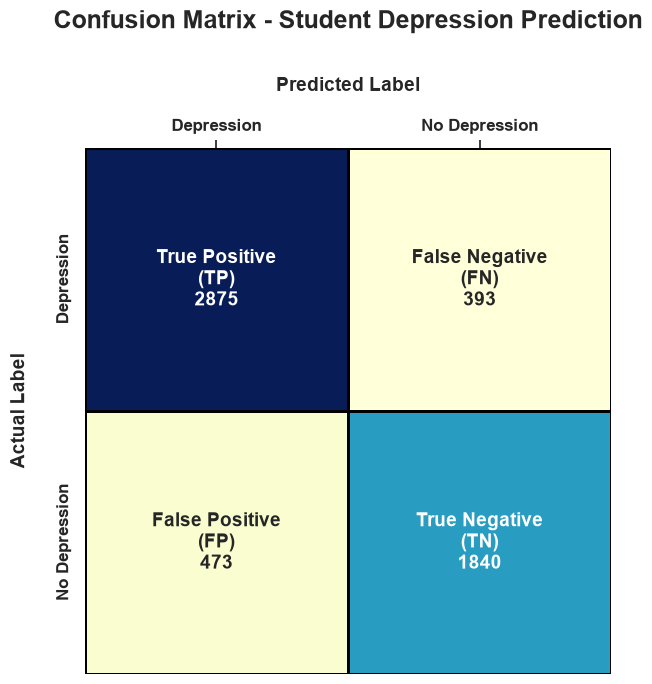


Confusion Matrix image saved successfully!
Location : outputs/confusion_matrix/confusion_matrix_final.png


In [19]:
# ==========================================================
# STEP 17 : Confusion Matrix (Final Presentation Version)
# Positive Class (Depression = 1) is shown first.
# ==========================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ----------------------------------------------------------
# Create confusion matrix
# labels=[1,0] places Depression first and No Depression second
# ----------------------------------------------------------
cm = confusion_matrix(y_test, y_pred, labels=[1, 0])

# Extract values
TP, FN, FP, TN = cm.ravel()

print("="*50)
print("CONFUSION MATRIX VALUES")
print("="*50)
print(f"True Positive  (TP) : {TP}")
print(f"False Negative (FN) : {FN}")
print(f"False Positive (FP) : {FP}")
print(f"True Negative  (TN) : {TN}")

# ----------------------------------------------------------
# Labels to display inside each box
# ----------------------------------------------------------
box_labels = [
    [f"True Positive\n(TP)\n{TP}",
     f"False Negative\n(FN)\n{FN}"],
    [f"False Positive\n(FP)\n{FP}",
     f"True Negative\n(TN)\n{TN}"]
]

# ----------------------------------------------------------
# Plot Confusion Matrix
# ----------------------------------------------------------
plt.figure(figsize=(8,7))

ax = sns.heatmap(
    cm,
    annot=box_labels,
    fmt="",
    cmap="YlGnBu",
    linewidths=2,
    linecolor="black",
    cbar=False,
    square=True,
    annot_kws={"fontsize":14, "fontweight":"bold"}
)

# Put Predicted Label at the TOP
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

# Axis Labels
ax.set_xlabel("Predicted Label", fontsize=14, fontweight="bold", labelpad=20)
ax.set_ylabel("Actual Label", fontsize=14, fontweight="bold", labelpad=20)

# Tick Labels
ax.set_xticklabels(["Depression", "No Depression"],
                   fontsize=12, fontweight="bold")

ax.set_yticklabels(["Depression", "No Depression"],
                   fontsize=12, fontweight="bold", rotation=90)

# Title
plt.title(
    "Confusion Matrix - Student Depression Prediction",
    fontsize=18,
    fontweight="bold",
    pad=35
)

plt.tight_layout()

# ----------------------------------------------------------
# Save image for report/presentation
# ----------------------------------------------------------
os.makedirs("../outputs/confusion_matrix", exist_ok=True)

plt.savefig(
    "../outputs/confusion_matrix/confusion_matrix_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConfusion Matrix image saved successfully!")
print("Location : outputs/confusion_matrix/confusion_matrix_final.png")

ROC CURVE PERFORMANCE
AUC Score : 0.9182


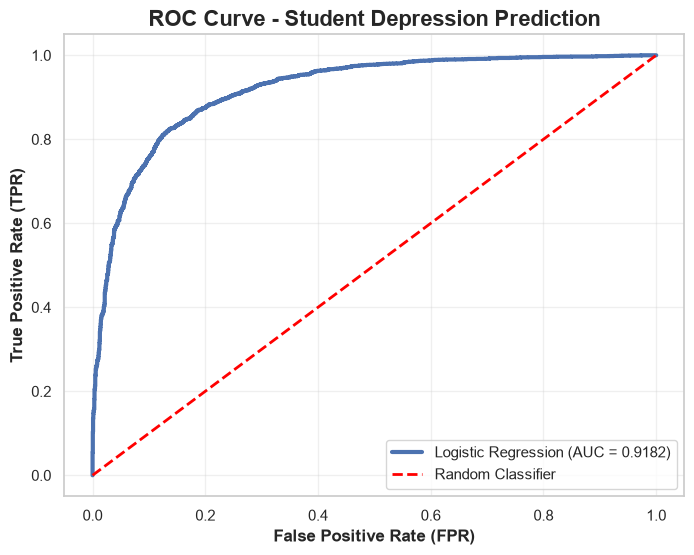

ROC Curve saved successfully!
Location : outputs/graphs/roc_curve.png


In [20]:
# ==========================================================
# STEP 18 : ROC Curve and AUC Score
# ROC Curve shows the classification performance of the model.
# ==========================================================

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import os

# Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC Score
auc_score = roc_auc_score(y_test, y_prob)

print("="*50)
print("ROC CURVE PERFORMANCE")
print("="*50)
print(f"AUC Score : {auc_score:.4f}")

# ----------------------------------------------------------
# Plot ROC Curve
# ----------------------------------------------------------
plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    linewidth=3,
    label=f"Logistic Regression (AUC = {auc_score:.4f})"
)

# Random classifier reference line
plt.plot([0,1], [0,1], linestyle="--", linewidth=2, color="red",
         label="Random Classifier")

# Labels and Title
plt.title("ROC Curve - Student Depression Prediction",
          fontsize=16, fontweight="bold")

plt.xlabel("False Positive Rate (FPR)", fontsize=12, fontweight="bold")
plt.ylabel("True Positive Rate (TPR)", fontsize=12, fontweight="bold")

plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")

# Save graph
os.makedirs("../outputs/graphs", exist_ok=True)

plt.savefig(
    "../outputs/graphs/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC Curve saved successfully!")
print("Location : outputs/graphs/roc_curve.png")

In [21]:
# ==========================================================
# STEP 18 : Precision, Recall and F1 Score Table
# ==========================================================
# We create a neat table of important evaluation metrics.

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Calculate metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Create a summary table
metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Value": [
        round(accuracy, 4),
        round(precision, 4),
        round(recall, 4),
        round(f1, 4)
    ]
})

print("MODEL PERFORMANCE SUMMARY")
display(metrics_df)

# Save metrics
metrics_df.to_csv("../outputs/metrics/model_metrics.csv", index=False)

print("Metrics saved successfully!")

MODEL PERFORMANCE SUMMARY


,Metric,Value
0,Accuracy,0.8448
1,Precision,0.8587
2,Recall,0.8797
3,F1 Score,0.8691


Metrics saved successfully!


Top 10 Most Important Features


,Feature,Coefficient,Importance
7,Have you ever had suicidal thoughts ?,1.214023,1.214023
2,Academic Pressure,1.166947,1.166947
9,Financial Stress,0.815621,0.815621
1,Age,-0.594291,0.594291
6,Dietary Habits,-0.438428,0.438428
8,Work/Study Hours,0.438246,0.438246
4,Study Satisfaction,-0.323545,0.323545
5,Sleep Duration,-0.205557,0.205557
10,Family History of Mental Illness,0.141954,0.141954
72,Degree_Class 12,-0.116607,0.116607


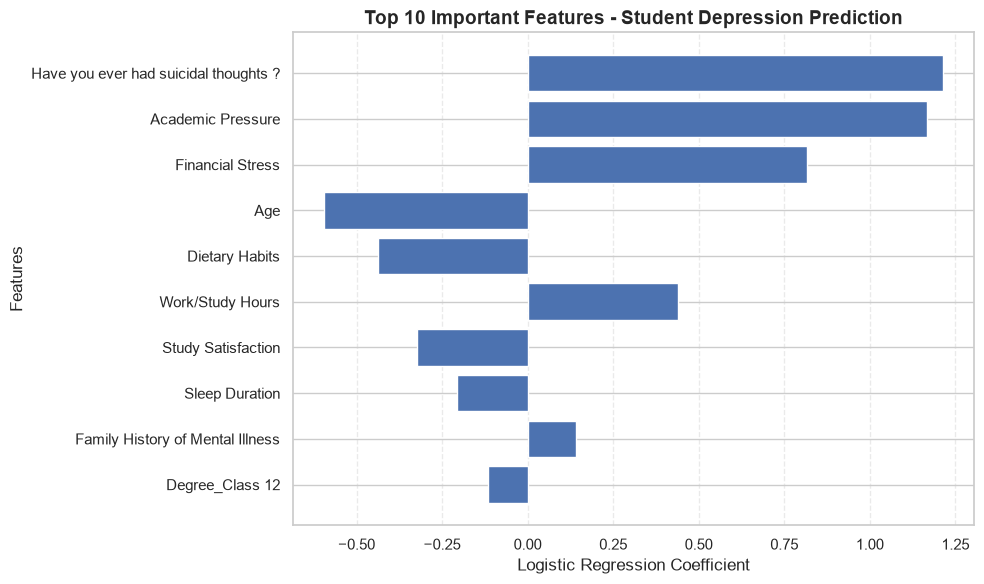

Feature Importance graph saved successfully!
Location : outputs/graphs/feature_importance.png


In [22]:
# ==========================================================
# STEP 18 : Feature Importance
# Find which features influence depression prediction the most.
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

# Get coefficients from trained Logistic Regression model
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

# Absolute value for ranking importance
importance["Importance"] = importance["Coefficient"].abs()

# Sort descending
importance = importance.sort_values(by="Importance", ascending=False)

print("Top 10 Most Important Features")
display(importance.head(10))

# Plot Top 10 Features
plt.figure(figsize=(10,6))

plt.barh(
    importance.head(10)["Feature"][::-1],
    importance.head(10)["Coefficient"][::-1]
)

plt.title("Top 10 Important Features - Student Depression Prediction",
          fontsize=14, fontweight="bold")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save graph
plt.savefig("../outputs/graphs/feature_importance.png", dpi=300)

plt.show()

print("Feature Importance graph saved successfully!")
print("Location : outputs/graphs/feature_importance.png")

Positive coefficient means the feature increases the chance of depression prediction. Negative coefficient means it decreases the chance.

In [23]:
# ==========================================================
# STEP 19 : Predict Depression for a New Student
# Example prediction using a student's details.
# ==========================================================

import pandas as pd

# Copy one student from dataset
new_student = X.iloc[[0]].copy()

# Modify values to create a new example student
new_student["Age"] = 21
new_student["Academic Pressure"] = 5
new_student["CGPA"] = 7.5
new_student["Study Satisfaction"] = 2
new_student["Work/Study Hours"] = 10
new_student["Financial Stress"] = 5

# Scale using the SAME scaler used during training
new_student_scaled = scaler.transform(new_student)

# Prediction
prediction = logistic_model.predict(new_student_scaled)[0]
probability = logistic_model.predict_proba(new_student_scaled)[0][1]

print("="*55)
print("NEW STUDENT DEPRESSION PREDICTION")
print("="*55)

display(new_student)

print(f"\nProbability of Depression : {probability:.2%}")

if prediction == 1:
    print("Prediction : Student is likely to have Depression.")
else:
    print("Prediction : Student is likely NOT to have Depression.")

NEW STUDENT DEPRESSION PREDICTION


,Gender,Age,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,...,Profession_Digital Marketer,Profession_Doctor,Profession_Educational Consultant,Profession_Entrepreneur,Profession_Lawyer,Profession_Manager,Profession_Pharmacist,Profession_Student,Profession_Teacher,Profession_UX/UI Designer
0,1,21,5,7.5,2,1.0,2.0,1,10,5,...,False,False,False,False,False,False,False,True,False,False



Probability of Depression : 99.03%
Prediction : Student is likely to have Depression.


In [24]:
# ==========================================================
# STEP 20 : Final Performance Summary Table
# This table summarizes all important evaluation metrics.
# ==========================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

# Create summary dataframe
summary = pd.DataFrame({
    "Evaluation Metric": [
        "Accuracy",
        "Precision",
        "Recall (Sensitivity)",
        "F1-Score",
        "ROC-AUC Score"
    ],
    "Value": [
        round(accuracy,4),
        round(precision,4),
        round(recall,4),
        round(f1,4),
        round(auc,4)
    ],
    "Percentage": [
        f"{accuracy*100:.2f}%",
        f"{precision*100:.2f}%",
        f"{recall*100:.2f}%",
        f"{f1*100:.2f}%",
        f"{auc*100:.2f}%"
    ]
})

print("="*60)
print("FINAL LOGISTIC REGRESSION MODEL PERFORMANCE SUMMARY")
print("="*60)

display(summary)

# Save metrics as CSV
summary.to_csv("../outputs/metrics/model_metrics_summary.csv", index=False)

print("\nPerformance summary saved successfully!")
print("Location : outputs/metrics/model_metrics_summary.csv")

FINAL LOGISTIC REGRESSION MODEL PERFORMANCE SUMMARY


,Evaluation Metric,Value,Percentage
0,Accuracy,0.8448,84.48%
1,Precision,0.8587,85.87%
2,Recall (Sensitivity),0.8797,87.97%
3,F1-Score,0.8691,86.91%
4,ROC-AUC Score,0.9182,91.82%



Performance summary saved successfully!
Location : outputs/metrics/model_metrics_summary.csv


In [25]:
# ==========================================================
# STEP 21 : Save Test Predictions
# Save actual labels, predicted labels and probabilities.
# ==========================================================

prediction_results = pd.DataFrame({
    "Actual_Depression": y_test.values,
    "Predicted_Depression": y_pred,
    "Probability_of_Depression": y_prob
})

print("First 10 Prediction Results")
display(prediction_results.head(10))

# Save CSV file
prediction_results.to_csv("../outputs/predictions/student_predictions.csv",
                          index=False)

print("\nPrediction CSV saved successfully!")
print("Location : outputs/predictions/student_predictions.csv")

First 10 Prediction Results


,Actual_Depression,Predicted_Depression,Probability_of_Depression
0,1,1,0.956391
1,0,1,0.807484
2,1,1,0.704361
3,0,0,0.263218
4,1,0,0.372051
5,0,0,0.126486
6,0,0,0.424498
7,0,1,0.890173
8,0,0,0.003373
9,1,1,0.983411



Prediction CSV saved successfully!
Location : outputs/predictions/student_predictions.csv


In [27]:
# ============================================================
# TEAM 16 INVESTIGATION - EXPERIMENT 1
# Threshold Comparison using YOUR notebook
# ============================================================

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Use YOUR notebook model
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

thresholds = [0.3, 0.5, 0.7]
results = []

for t in thresholds:
    y_pred_threshold = (y_prob >= t).astype(int)

    results.append({
        "Threshold": t,
        "Accuracy": round(accuracy_score(y_test, y_pred_threshold), 4),
        "Precision": round(precision_score(y_test, y_pred_threshold), 4),
        "Recall": round(recall_score(y_test, y_pred_threshold), 4),
        "F1-Score": round(f1_score(y_test, y_pred_threshold), 4)
    })

threshold_df = pd.DataFrame(results)

print("="*60)
print("TEAM 16 - THRESHOLD COMPARISON")
print("="*60)

display(threshold_df)

TEAM 16 - THRESHOLD COMPARISON


,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.3,0.8276,0.7975,0.9458,0.8653
1,0.5,0.8448,0.8587,0.8797,0.8691
2,0.7,0.8267,0.9084,0.7830,0.8411


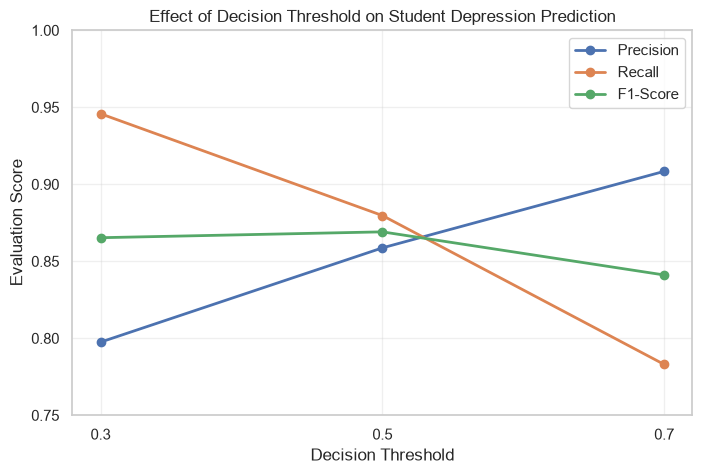

Threshold comparison graph saved successfully!
Location : ../outputs/graphs/threshold_comparison.png


In [29]:
# ============================================================
# STEP 23 : Threshold vs Evaluation Metrics Graph
# ============================================================

import matplotlib.pyplot as plt
import os

# Create outputs/graphs folder if it doesn't exist
os.makedirs("../outputs/graphs", exist_ok=True)

# Create graph
plt.figure(figsize=(8,5))

# Plot metrics
plt.plot(threshold_df["Threshold"], threshold_df["Precision"],
         marker="o", linewidth=2, label="Precision")

plt.plot(threshold_df["Threshold"], threshold_df["Recall"],
         marker="o", linewidth=2, label="Recall")

plt.plot(threshold_df["Threshold"], threshold_df["F1-Score"],
         marker="o", linewidth=2, label="F1-Score")

# Formatting
plt.title("Effect of Decision Threshold on Student Depression Prediction")
plt.xlabel("Decision Threshold")
plt.ylabel("Evaluation Score")
plt.xticks([0.3, 0.5, 0.7])
plt.ylim(0.75, 1.0)

plt.grid(True, alpha=0.3)
plt.legend()

# Save graph for report
plt.savefig("../outputs/graphs/threshold_comparison.png",
            dpi=300,
            bbox_inches="tight")

# Show graph
plt.show()

print("Threshold comparison graph saved successfully!")
print("Location : ../outputs/graphs/threshold_comparison.png")

In [30]:

# ============================================================
# STEP 24 : Save Threshold Comparison Table
# ============================================================

import os

# Create metrics folder if it doesn't exist
os.makedirs("../outputs/metrics", exist_ok=True)

# Save threshold comparison table
threshold_df.to_csv("../outputs/metrics/threshold_comparison.csv", index=False)

print("Threshold comparison table saved successfully!")
print("Location : ../outputs/metrics/threshold_comparison.csv")

display(threshold_df)


Threshold comparison table saved successfully!
Location : ../outputs/metrics/threshold_comparison.csv


,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.3,0.8276,0.7975,0.9458,0.8653
1,0.5,0.8448,0.8587,0.8797,0.8691
2,0.7,0.8267,0.9084,0.7830,0.8411


##  Investigation Conclusion 1

### Objective

To investigate how different decision thresholds affect the evaluation of a Logistic Regression model for student depression prediction.

### Observation

The model was evaluated using three thresholds: **0.3, 0.5, and 0.7**.

| Threshold | Key Observation |
|-----------|-----------------|
| **0.3** | Highest Recall (94.58%) but lower Precision. More depressed students are detected, but false positives increase. |
| **0.5** | Highest F1-Score (86.91%). Provides the best balance between Precision and Recall. |
| **0.7** | Highest Precision (90.84%) but lower Recall. Fewer false positives, but more depressed students are missed. |

### Conclusion

The investigation shows that **Accuracy alone is not enough** to evaluate a mental health prediction model. The choice of decision threshold changes Precision, Recall, and F1-Score, leading to different conclusions about model performance. Threshold **0.5** provides the best balance for this dataset, while threshold **0.3** is more suitable when identifying as many depression cases as possible is the priority.


## Investigation 2 : Feature Importance Analysis

### Objective

To identify the features that have the greatest influence on student depression prediction using Logistic Regression coefficients.

### Observation

The feature importance graph ranks the top 10 features based on the absolute value of their Logistic Regression coefficients.

### Key Findings

- **Have you ever had suicidal thoughts?** is the most influential positive feature.
- **Academic Pressure** is the second strongest predictor.
- **Financial Stress** also has a strong positive influence.
- **Age**, **Dietary Habits**, and **Study Satisfaction** have negative coefficients, indicating an inverse relationship in this model.
- **Work/Study Hours** and **Family History of Mental Illness** also contribute to the prediction.

### Conclusion

The Logistic Regression model indicates that mental health history and academic-related stress factors contribute more strongly to depression prediction than demographic features in this dataset.


## Investigation 3 : Confusion Matrix Error Analysis

### Objective

To analyze the prediction errors made by the Logistic Regression model.

### Observation

The confusion matrix produced the following results:

- **True Positive (TP): 2875**
- **True Negative (TN): 1840**
- **False Positive (FP): 473**
- **False Negative (FN): 393**

### Analysis

- The model correctly identified **2875 students with depression**.
- The model correctly identified **1840 students without depression**.
- **473 students without depression** were incorrectly predicted as depressed.
- **393 depressed students** were missed by the model.

### Conclusion

For a student mental health prediction system, minimizing **False Negatives** is important because missing a depressed student may delay timely intervention and support.


# Team 16 Investigation: Metric Choice

## Research Question

How does the choice of evaluation metric change the conclusion about a model?

## Experimental Design

The same Logistic Regression model was evaluated on the same test dataset using multiple evaluation metrics: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

The model, training data, test data, and predictions were kept unchanged. Only the evaluation perspective was changed.

## Results and Analysis

The model achieved an Accuracy of 84.48%. This indicates that approximately 84% of the test predictions were correct overall.

However, Accuracy does not describe the types of errors made by the model. Precision was 85.87%, while Recall was higher at 87.97%. This difference shows that the model's ability to detect actual depression cases was different from the reliability of its positive predictions.

The F1-Score was 86.91%, providing a combined measure of Precision and Recall. The ROC-AUC was 91.82%, indicating strong discrimination between the two classes across different probability thresholds.

Therefore, the same model can appear different depending on the metric used. Accuracy focuses on overall correctness, Precision focuses on false positive errors, Recall focuses on false negative errors, F1-Score balances Precision and Recall, and ROC-AUC evaluates discrimination across thresholds.

## Why the Conclusions Differ

Different metrics emphasize different aspects of model behaviour. Therefore, there is no single metric that completely describes classification performance.

For this student depression prediction task, Recall is particularly informative because it shows how many actual depression cases were detected. Precision is also important because it indicates how reliable the model's positive predictions are.

The results demonstrate that selecting an evaluation metric can change the interpretation of the same model without changing the model itself.

## Investigation Conclusion

The investigation shows that the choice of evaluation metric can change the conclusion about model performance. Accuracy alone gives an overall measure of correctness, while Precision, Recall, F1-Score, and ROC-AUC provide additional information about errors, class detection, balance, and discrimination.

Thus, model evaluation should use multiple appropriate metrics rather than relying on a single metric.

# Critical Evaluation and Limitations

## Limitations

1. **Single train-test split:**  
   The evaluation is based on one train-test split. A different split may produce different metric values.

2. **Dataset generalization:**  
   The results are based on the Student Depression Dataset used in this project. Therefore, the findings may not represent every student population or educational institution.

3. **Model limitation:**  
   Logistic Regression is a relatively simple classification model and may not capture complex non-linear relationships between the features and the depression outcome.

4. **Metric interpretation:**  
   No single evaluation metric is sufficient to describe all aspects of model performance. Accuracy, Precision, Recall, F1-Score, and ROC-AUC provide different perspectives.

5. **Threshold limitation:**  
   The threshold experiment considered only 0.3, 0.5, and 0.7. Other thresholds may produce different Precision, Recall, and F1-Score values.

6. **Prediction versus diagnosis:**  
   The model evaluates predictive patterns in the dataset and should not be interpreted as a clinical diagnostic system or as evidence of causation.

## Reliability of the Findings

The main conclusion is supported by multiple evaluation metrics calculated from the same test predictions. However, the findings should be interpreted within the limitations of the dataset, model, and experimental setup.

# Final Investigation Conclusion

## Conclusion

This investigation examined how the choice of evaluation metric changes the interpretation of a Logistic Regression model for student depression prediction.

The same model and the same test predictions produced different results depending on the evaluation metric used. The model achieved an Accuracy of **84.48%**, Precision of **85.87%**, Recall of **87.97%**, F1-Score of **86.91%**, and ROC-AUC of **91.82%**.

These results show that each metric provides a different view of model performance. Accuracy measures overall correctness, Precision measures the reliability of positive predictions, Recall measures the ability to detect actual positive cases, F1-Score balances Precision and Recall, and ROC-AUC measures the model's ability to distinguish between the two classes across different probability thresholds.

The threshold analysis also showed that changing the decision threshold changes the balance between Precision and Recall. At a threshold of **0.3**, Recall increased to **94.58%** while Precision decreased to **79.75%**. At a threshold of **0.7**, Precision increased to **90.84%** while Recall decreased to **78.30%**. Among the three thresholds tested, **0.5 produced the highest F1-Score of 86.91%**.

Therefore, the choice of evaluation metric can change the interpretation of the same model without changing the model itself. Model performance should not be judged using Accuracy alone. Multiple appropriate metrics should be considered because different metrics highlight different aspects of prediction performance.

Overall, the findings support the hypothesis that **different evaluation metrics can lead to different conclusions about the same model**.